## CNN CIA Test 1
### Instructions
**Marks: 15**
- Identify and correct the errors without completely rewriting the program.
- Execute the corrected program successfully.

I0000 00:00:1791175391.169453   70345 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791175391.217400   70345 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791175392.107102   70345 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


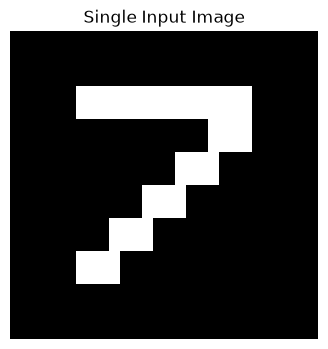

Input shape: (1, 28, 28, 1)
Minimum: 0.0
Maximum: 255.0


/mnt/data/college/5_Tri/ami/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1791175392.862849   70345 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 6, 6, 8)        │         2,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 3, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 72)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,336 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,480 (21.41 KB)

 Trainable params: 5,480 (21.41 KB)

 Non-trainable params: 0 (0.00 B)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step

Final feature representation shape: (1, 32)
Forward pass completed successfully.


AttributeError: The layer sequential has never been called and thus has no defined input.

In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ============================================================
# CNN DEBUGGING TEST
# ============================================================

# Create one local 28 x 28 grayscale image
image = np.zeros((28, 28, 1), dtype=np.float32)

image[5:8, 6:22] = 1.0
image[8:11, 18:22] = 1.0
image[11:14, 15:19] = 1.0
image[14:17, 12:16] = 1.0
image[17:20, 9:13] = 1.0
image[20:23, 6:10] = 1.0

# Display the input image
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Single Input Image")
plt.axis("off")
plt.show()

# Normalize the image
image = image * 255.0

# Add batch dimension
image = image.reshape(1, 28, 28, 1)
input_shape=(28, 28, 1)


print("Input shape:", image.shape)
print("Minimum:", image.min())
print("Maximum:", image.max())

# ============================================================
# CNN MODEL
# ============================================================

model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=(5, 5),
        activation="sigmoid",
        input_shape=(28, 28, 1)
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(3, 3),
        strides=(3, 3)
    ),

    tf.keras.layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        activation="sigmoid"
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        32,
        activation="sigmoid"
    )
])

model.summary()

# ============================================================
# FORWARD PASS
# ============================================================

output = model.predict(image)

print("\nFinal feature representation shape:", output.shape)
print("Forward pass completed successfully.")

# ============================================================
# FIRST CONVOLUTION FEATURE MAP
# ============================================================

feature_model = tf.keras.Model(
    inputs=model.input,
    outputs=model.layers[0].output,
    
)

feature_maps = feature_model(image, training=False)

print("First convolution output shape:", feature_maps.shape)

plt.figure(figsize=(5, 4))
plt.imshow(feature_maps[0, :, :, 0], cmap="gray")
plt.title("First Convolution Feature Map")
plt.axis("off")
plt.show()
